# Tokenización: BPE desde cero

Un modelo de lenguaje no ve palabras sino *tokens*. BPE parte de caracteres y fusiona el par más frecuente una y otra vez. Aquí lo implementamos (`research_paths.bpe`) y verificamos que da **exactamente** las mismas fusiones que la librería `tokenizers` de Hugging Face.

In [1]:
import matplotlib.pyplot as plt

from common import set_seed, setup_style

setup_style()
rng = set_seed(42)

In [2]:
CORPUS = [
    "el aprendizaje por refuerzo estudia agentes que aprenden por recompensa",
    "la investigación en aprendizaje automático usa datos para aprender modelos",
    "la información de los datos permite aprender representaciones",
    "los modelos de lenguaje aprenden representaciones de palabras",
    "la moniliasis del cacao es una enfermedad de las mazorcas",
    "las enfermedades del cacao reducen la producción de las fincas",
]

In [3]:
from research_paths.bpe import encode, train_bpe

merges = train_bpe(CORPUS, 40)
merges[:12]

[('e', 'n'),
 ('d', 'e'),
 ('p', 'r'),
 ('e', 's'),
 ('l', 'a'),
 ('a', 'c'),
 ('a', 'pr'),
 ('o', 's'),
 ('apr', 'en'),
 ('r', 'e'),
 ('a', 's'),
 ('d', 'a')]

Las primeras fusiones son pares frecuentes del español (`en`, `de`, `es`, `la`) y enseguida aparecen raíces largas como `apr` + `en` → `apren`.

In [4]:
for w in ["aprendizaje", "investigación", "moniliasis", "recompensas"]:
    print(f"{w:15s} → {encode(w, merges)}")

aprendizaje     → ['aprend', 'iz', 'aje']
investigación   → ['in', 'v', 'es', 'ti', 'g', 'aci', 'ón']
moniliasis      → ['mo', 'n', 'i', 'l', 'i', 'as', 'i', 's']
recompensas     → ['re', 'co', 'm', 'p', 'en', 's', 'as']


## Contra `tokenizers`

El desempate importa: ante dos pares igual de frecuentes, `tokenizers` elige el de ids menores (alfabeto ordenado y luego orden de creación).

In [5]:
import json

from tokenizers import Tokenizer, models, pre_tokenizers, trainers

tok = Tokenizer(models.BPE())
tok.pre_tokenizer = pre_tokenizers.WhitespaceSplit()
alphabet = {c for line in CORPUS for c in line if c != " "}
tok.train_from_iterator(
    CORPUS, trainers.BpeTrainer(vocab_size=len(alphabet) + 40, min_frequency=0, show_progress=False)
)
ref = [tuple(m) for m in json.loads(tok.to_str())["model"]["merges"]]
assert ref == merges
print("Mismas 40 fusiones que tokenizers ✓")

Mismas 40 fusiones que tokenizers ✓


## Fertilidad: tokens por palabra

Más fusiones → menos tokens por palabra, pero un vocabulario más grande. Las palabras que no están en el corpus («moniliasis») se parten en pedazos: así un modelo nunca tiene palabras desconocidas.

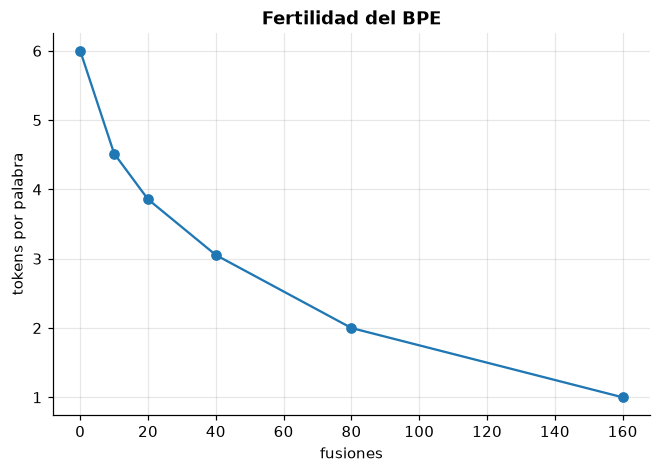

In [6]:
words = " ".join(CORPUS).split()
sizes = [0, 10, 20, 40, 80, 160]
fert = [len(encode(" ".join(words), train_bpe(CORPUS, n))) / len(words) for n in sizes]
fig, ax = plt.subplots()
ax.plot(sizes, fert, marker="o")
ax.set(xlabel="fusiones", ylabel="tokens por palabra", title="Fertilidad del BPE");

El notebook 06 muestra el tokenizador real de XLM-R (SentencePiece, 250 000 tokens) con palabras en español e inglés.